# CyberSentry — 02 · Preprocessing & Feature Selection

**Input:** `data/processed/cicids2017_clean.parquet` (output of notebook 01)
**Output:**
- `data/processed/train.parquet`, `val.parquet`, `test.parquet` — the same splits used by **both** the ML and DL stages
- `models/preprocessing/selected_features.json` — final feature list
- `models/preprocessing/scaler.joblib` — scaler fitted on the training set only

Steps:
1. Drop constant columns and non-feature columns
2. Split into **train / validation / test (70 / 15 / 15)**, stratified by attack type so rare attacks appear in every split
3. Feature selection **on the training set only** (no information leaks from test data):
   - remove highly correlated (redundant) features
   - rank the rest with Random Forest importance and Mutual Information
   - keep the smallest set that covers 95% of total importance
4. Fit a scaler on the training set and save everything

> Every decision here uses **training data only**. The test set is touched once, at the very end, for evaluation.

## 1. Setup

In [1]:
import json
import time
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import mutual_info_classif
from sklearn.preprocessing import StandardScaler

pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 140)
SEED = 42

ROOT = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
PROC_DIR = ROOT / "data" / "processed"
ART_DIR = ROOT / "models" / "preprocessing"
ART_DIR.mkdir(parents=True, exist_ok=True)

# Tunable settings (documented in the report)
CORR_THRESHOLD = 0.95        # drop one of any feature pair correlated above this
IMPORTANCE_COVERAGE = 0.95   # keep features covering this share of RF importance
SAMPLE_CAP_PER_CLASS = 20_000  # rows per class used for feature ranking (speed)

data = pd.read_parquet(PROC_DIR / "cicids2017_clean.parquet")
print(f"Loaded clean data: {data.shape[0]:,} rows x {data.shape[1]} columns")

Loaded clean data: 2,498,185 rows x 80 columns


## 2. Drop constant and non-feature columns

In [2]:
NON_FEATURES = ["Label", "binary_label", "source_file"]
feature_cols = [c for c in data.columns if c not in NON_FEATURES]

constant_cols = [c for c in feature_cols if data[c].nunique(dropna=False) <= 1]
data = data.drop(columns=constant_cols)
feature_cols = [c for c in feature_cols if c not in constant_cols]

print(f"Dropped {len(constant_cols)} constant columns: {constant_cols}")
print(f"Remaining features: {len(feature_cols)}")

Dropped 8 constant columns: ['Bwd PSH Flags', 'Bwd URG Flags', 'Fwd Avg Bytes/Bulk', 'Fwd Avg Packets/Bulk', 'Fwd Avg Bulk Rate', 'Bwd Avg Bytes/Bulk', 'Bwd Avg Packets/Bulk', 'Bwd Avg Bulk Rate']
Remaining features: 69


## 3. Train / validation / test split (70 / 15 / 15)

Stratified on the multi-class `Label`, so every split keeps the same proportion of each attack type, including very rare ones like Heartbleed.

- **train** → fitting models and choosing features
- **val** → tuning and early stopping (especially for DL)
- **test** → final, one-time evaluation reported in the project

In [3]:
y_all = data["Label"].astype(str)
train_df, temp_df = train_test_split(data, test_size=0.30, stratify=y_all, random_state=SEED)
val_df, test_df = train_test_split(temp_df, test_size=0.50, stratify=temp_df["Label"].astype(str), random_state=SEED)
del temp_df

split_counts = pd.DataFrame({
    "train": train_df["Label"].value_counts(),
    "val": val_df["Label"].value_counts(),
    "test": test_df["Label"].value_counts(),
}).fillna(0).astype(int).sort_values("train", ascending=False)
split_counts.loc["TOTAL"] = split_counts.sum()
print(f"train {len(train_df):,} | val {len(val_df):,} | test {len(test_df):,}")
split_counts

train 1,748,729 | val 374,728 | test 374,728


,train,val,test
Label,,,
BENIGN,1450710,310867,310867
DoS Hulk,120992,25927,25927
DDoS,89610,19202,19202
PortScan,63486,13604,13604
DoS GoldenEye,7200,1543,1543
FTP-Patator,4152,889,890
DoS slowloris,3769,808,808
DoS Slowhttptest,3660,784,784
SSH-Patator,2253,483,483


## 4. Feature-ranking sample (from training data only)

Ranking ~70 features on 1.7 million rows is slow and dominated by BENIGN. Instead we take a **class-capped sample** of the training set: up to 20,000 rows per class (all rows for rarer classes). This gives every attack type a fair voice in the ranking.

In [4]:
def capped_sample(df, cap):
    parts = [g.sample(min(len(g), cap), random_state=SEED)
             for _, g in df.groupby("Label", observed=True)]
    return pd.concat(parts)

rank_sample = capped_sample(train_df, SAMPLE_CAP_PER_CLASS)
X_rank = rank_sample[feature_cols]
y_rank = rank_sample["Label"].astype(str)
print(f"Ranking sample: {len(rank_sample):,} rows")
y_rank.value_counts().to_frame("rows in sample")

Ranking sample: 103,931 rows


,rows in sample
Label,
BENIGN,20000
DDoS,20000
DoS Hulk,20000
PortScan,20000
DoS GoldenEye,7200
FTP-Patator,4152
DoS slowloris,3769
DoS Slowhttptest,3660
SSH-Patator,2253


## 5. Remove highly correlated features

Many CIC-IDS2017 features are near-copies of each other (e.g. totals vs. averages of the same packets). For every pair with |correlation| > 0.95 we drop one, keeping the one that appears first in the dataset. Redundant features add training time without adding information.

In [5]:
corr = X_rank.astype(np.float64).corr().abs()
upper = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1))

to_drop, drop_reason = [], {}
for col in upper.columns:
    partners = upper.index[upper[col] > CORR_THRESHOLD].tolist()
    partners = [p for p in partners if p not in to_drop]
    if partners:
        to_drop.append(col)
        drop_reason[col] = f"{upper.loc[partners[0], col]:.3f} with '{partners[0]}'"

uncorrelated = [c for c in feature_cols if c not in to_drop]
print(f"Dropped {len(to_drop)} highly correlated features, {len(uncorrelated)} remain\n")
pd.Series(drop_reason, name="correlation").to_frame()

Dropped 22 highly correlated features, 47 remain



,correlation
Total Backward Packets,1.000 with 'Total Fwd Packets'
Total Length of Bwd Packets,0.998 with 'Total Fwd Packets'
Bwd Packet Length Mean,0.962 with 'Bwd Packet Length Max'
Bwd Packet Length Std,0.990 with 'Bwd Packet Length Max'
Fwd IAT Total,0.999 with 'Flow Duration'
Fwd IAT Max,1.000 with 'Flow IAT Max'
Fwd Header Length,1.000 with 'Total Fwd Packets'
Bwd Header Length,1.000 with 'Total Fwd Packets'
Fwd Packets/s,0.952 with 'Flow Packets/s'
Max Packet Length,0.991 with 'Bwd Packet Length Max'


## 6. Rank features: Random Forest importance + Mutual Information

Two independent methods, so the choice isn't based on one model's opinion:
- **Random Forest importance** — how much each feature helps a tree ensemble separate the attack types
- **Mutual Information** — a model-free score of how much each feature tells us about the label

In [6]:
t0 = time.time()
rf = RandomForestClassifier(n_estimators=100, max_depth=20, n_jobs=-1,
                            class_weight="balanced", random_state=SEED)
rf.fit(X_rank[uncorrelated], y_rank)
rf_imp = pd.Series(rf.feature_importances_, index=uncorrelated)
print(f"Random Forest ranking done in {time.time() - t0:.0f}s")

t0 = time.time()
mi_idx = capped_sample(rank_sample, 5_000).index
mi = mutual_info_classif(X_rank.loc[mi_idx, uncorrelated], y_rank.loc[mi_idx], random_state=SEED)
mi_imp = pd.Series(mi, index=uncorrelated)
print(f"Mutual Information done in {time.time() - t0:.0f}s")

ranking = pd.DataFrame({"rf_importance": rf_imp, "mutual_info": mi_imp})
ranking["rf_rank"] = ranking["rf_importance"].rank(ascending=False).astype(int)
ranking["mi_rank"] = ranking["mutual_info"].rank(ascending=False).astype(int)
ranking = ranking.sort_values("rf_importance", ascending=False)
ranking["rf_cumulative"] = ranking["rf_importance"].cumsum() / ranking["rf_importance"].sum()
ranking.round(4)

Random Forest ranking done in 2s
Mutual Information done in 9s


,rf_importance,mutual_info,rf_rank,mi_rank,rf_cumulative
Destination Port,0.0833,1.2227,1,17,0.0833
Init_Win_bytes_backward,0.0708,1.3004,2,16,0.1541
Fwd Packet Length Max,0.0524,1.5763,3,11,0.2065
Packet Length Mean,0.0466,1.7920,4,1,0.2531
Bwd Packet Length Max,0.0452,1.3642,5,15,0.2984
Total Length of Fwd Packets,0.0405,1.5962,6,8,0.3389
Bwd Packets/s,0.0391,1.5870,7,10,0.3779
Flow Duration,0.0326,1.6948,8,4,0.4106
Flow Packets/s,0.0326,1.6824,9,5,0.4431
min_seg_size_forward,0.0294,0.7631,10,28,0.4725


## 7. Choose the final feature set

We keep the smallest number of features (in Random Forest order) that together cover **95%** of total importance. Any feature that falls outside that cut but is in the **Mutual Information top 10** is added back, so a feature that's strongly informative by the second method isn't lost.

In [7]:
n_keep = int((ranking["rf_cumulative"] < IMPORTANCE_COVERAGE).sum()) + 1
selected = ranking.index[:n_keep].tolist()
mi_top10 = mi_imp.sort_values(ascending=False).index[:10].tolist()
added_back = [f for f in mi_top10 if f not in selected]
selected += added_back

print(f"Kept {n_keep} features by RF coverage ({IMPORTANCE_COVERAGE:.0%})")
print(f"Added back from MI top-10: {added_back if added_back else 'none'}")
print(f"\nFINAL: {len(selected)} features (from {len(feature_cols)} after constants were dropped)")
for i, f in enumerate(selected, 1):
    print(f"  {i:2}. {f}")

Kept 32 features by RF coverage (95%)
Added back from MI top-10: none

FINAL: 32 features (from 69 after constants were dropped)
   1. Destination Port
   2. Init_Win_bytes_backward
   3. Fwd Packet Length Max
   4. Packet Length Mean
   5. Bwd Packet Length Max
   6. Total Length of Fwd Packets
   7. Bwd Packets/s
   8. Flow Duration
   9. Flow Packets/s
  10. min_seg_size_forward
  11. Packet Length Variance
  12. Fwd IAT Std
  13. Fwd IAT Mean
  14. Flow IAT Std
  15. Flow IAT Max
  16. Flow IAT Mean
  17. Fwd Packet Length Mean
  18. Total Fwd Packets
  19. Init_Win_bytes_forward
  20. Bwd IAT Total
  21. Fwd Packet Length Std
  22. Flow Bytes/s
  23. Flow IAT Min
  24. Fwd IAT Min
  25. Bwd Packet Length Min
  26. Active Min
  27. PSH Flag Count
  28. Bwd IAT Std
  29. Bwd IAT Mean
  30. Bwd IAT Min
  31. Idle Min
  32. Bwd IAT Max


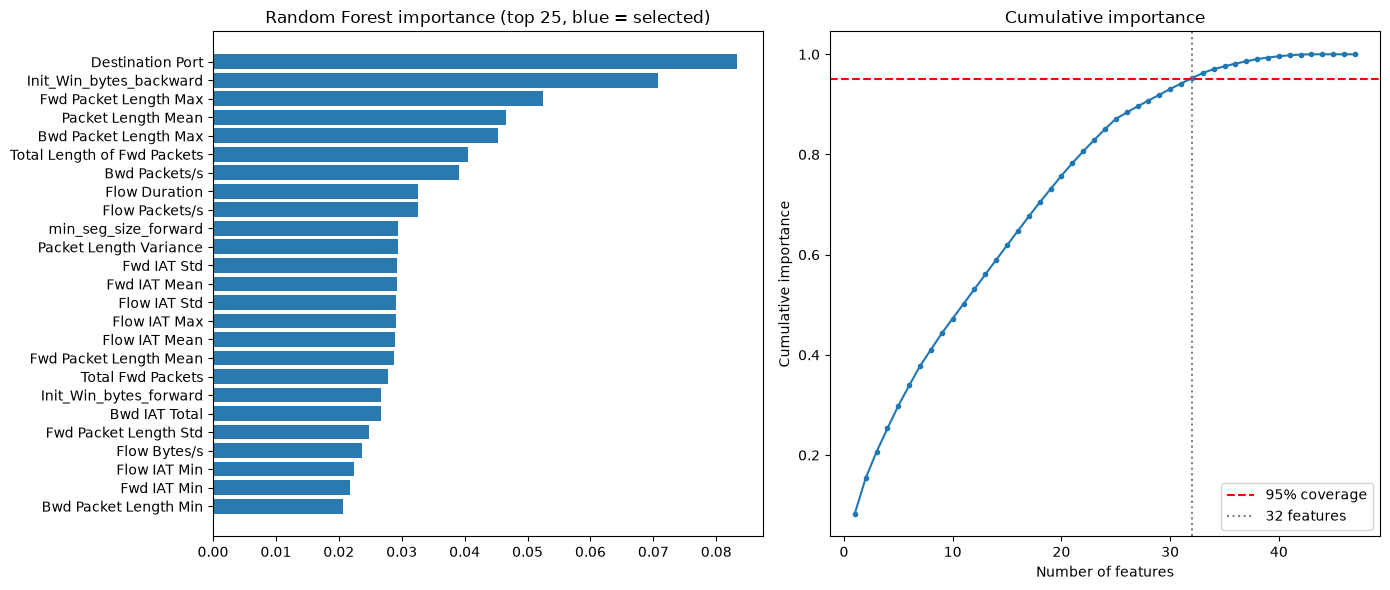

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(14, 6))
top = ranking.head(25)
ax[0].barh(top.index[::-1], top["rf_importance"][::-1],
           color=["#2a7ab0" if f in selected else "#b0b0b0" for f in top.index[::-1]])
ax[0].set_title("Random Forest importance (top 25, blue = selected)")
ax[1].plot(range(1, len(ranking) + 1), ranking["rf_cumulative"].values, marker=".")
ax[1].axhline(IMPORTANCE_COVERAGE, color="red", ls="--", label=f"{IMPORTANCE_COVERAGE:.0%} coverage")
ax[1].axvline(n_keep, color="gray", ls=":", label=f"{n_keep} features")
ax[1].set_xlabel("Number of features"); ax[1].set_ylabel("Cumulative importance")
ax[1].set_title("Cumulative importance"); ax[1].legend()
plt.tight_layout(); plt.show()

## 8. Scaling (fit on training data only)

Distance- and gradient-based models (One-Class SVM, MLP, LSTM, etc.) need features on a similar scale. Tree models (Random Forest, XGBoost, Isolation Forest) don't, so the splits are saved **unscaled** and each model notebook applies the saved scaler only when needed.

The scaler is fitted **on the training set only**, so nothing about the validation or test data influences it.

In [9]:
scaler = StandardScaler()
scaler.fit(train_df[selected].astype(np.float64))
joblib.dump(scaler, ART_DIR / "scaler.joblib")

# quick check that scaling behaves on train
scaled_check = pd.DataFrame(scaler.transform(train_df[selected].head(100_000).astype(np.float64)), columns=selected)
print("Mean of scaled features (should be ~0):", round(float(scaled_check.mean().abs().mean()), 3))
print("Saved scaler ->", ART_DIR / "scaler.joblib")

Mean of scaled features (should be ~0): 0.004
Saved scaler -> d:\Engineering\SEM 5\MINI PROJECT II\Cybersentry\models\preprocessing\scaler.joblib


## 9. Save splits and feature list

In [10]:
keep_cols = selected + ["Label", "binary_label"]
for name, df in [("train", train_df), ("val", val_df), ("test", test_df)]:
    out = df[keep_cols].reset_index(drop=True)
    out["Label"] = out["Label"].astype(str)
    out.to_parquet(PROC_DIR / f"{name}.parquet", index=False)
    print(f"Saved {name}.parquet  {out.shape[0]:>9,} rows x {out.shape[1]} cols")

meta = {
    "selected_features": selected,
    "n_features": len(selected),
    "dropped_constant": constant_cols,
    "dropped_correlated": to_drop,
    "corr_threshold": CORR_THRESHOLD,
    "importance_coverage": IMPORTANCE_COVERAGE,
    "split": {"train": 0.70, "val": 0.15, "test": 0.15, "stratified_on": "Label", "seed": SEED},
    "scaler": "StandardScaler fitted on train only (models/preprocessing/scaler.joblib)",
}
with open(ART_DIR / "selected_features.json", "w") as f:
    json.dump(meta, f, indent=2)
print("Saved", ART_DIR / "selected_features.json")

Saved train.parquet  1,748,729 rows x 34 cols
Saved val.parquet    374,728 rows x 34 cols
Saved test.parquet    374,728 rows x 34 cols
Saved d:\Engineering\SEM 5\MINI PROJECT II\Cybersentry\models\preprocessing\selected_features.json


## 10. Summary

*(Fill in the numbers from the outputs above.)*

- **Constant columns dropped:** see section 2
- **Highly correlated features dropped (|r| > 0.95):** see section 5
- **Final feature set:** see section 7 — chosen by Random Forest importance (95% coverage) cross-checked with Mutual Information
- **Splits:** 70 / 15 / 15, stratified by attack type — identical splits are used by the ML and DL stages so results are directly comparable
- **No data leakage:** feature selection and scaling used the training set only

Next: `03_ml_anomaly_detection.ipynb` — compare Isolation Forest, One-Class SVM, Random Forest and XGBoost on `binary_label`.